# Lab 02: Visualization of Intrusion Detection (IDS) Alerts

---
## 0. Objective and plan
An IDS such as Snort or Suricata produces thousands of alerts per day. Most are low-priority noise, so analysts suffer from *alert fatigue*. The goal is to use visualization to find the few alerts that matter.

| Step | What we do |
|---|---|
| 1 | Simulate one day of IDS alerts (normal noise + a benign vulnerability scanner + **one injected attack**) |
| 2 | Explore the data |
| 3 | Produce 3 visualizations that expose the anomaly |
| 4 | Define **one** simple detection rule |
| 5 | Evaluate it on anomalous data, on normal-only data, and across thresholds |
| 6 | Present the findings |

**Injected anomaly:** at 14:20 an external IP launches a burst of *Log4j RCE* exploit attempts (priority 1) against the web servers.  
**Trap for the rule:** an internal, authorised vulnerability scanner generates *more* alerts than the attacker, but at low priority. A rule based on raw volume would be fooled by it.

## 1. Imports and configuration

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime, timedelta

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figures", exist_ok=True)

BLUE, RED, GREY = "#0B6E93", "#C0392B", "#7F8C8D"
DAY = datetime(2026, 10, 19)

## 2. Dataset: simulating IDS alerts
Each row is one alert, with the fields a Snort/Suricata log would give us:

| Column | Meaning |
|---|---|
| `timestamp` | When the alert fired |
| `src_ip`, `dst_ip`, `dst_port` | Connection that triggered the alert |
| `signature` | Name of the rule that matched |
| `category` | Class of the signature (Exploit, Scan, Policy, ...) |
| `priority` | 1 = high, 2 = medium, 3 = low (Snort convention) |
| `is_attack` | **Ground truth label**, used only for evaluation, never by the detection rule |

The generator is a function so we can build (a) a day **with** the attack and (b) a **normal-only** day with a different seed to measure false alarms.

In [ ]:
SIGNATURES = [
    # (signature, category, priority, relative frequency in normal traffic)
    ("ICMP Echo Request",                    "Network",    3, 0.26),
    ("ET POLICY Dropbox DNS Lookup",         "Policy",     3, 0.20),
    ("SNMP public community access",         "Network",    3, 0.12),
    ("ET SCAN Nmap Scripting Engine",        "Scan",       2, 0.14),
    ("SSH Login Failure",                    "Auth",       2, 0.12),
    ("ET WEB_SERVER SQL Injection Attempt",  "Web-Attack", 1, 0.07),
    ("MALWARE Known C2 Beacon",              "Malware",    1, 0.05),
    ("ET EXPLOIT Apache Log4j RCE Attempt",  "Exploit",    1, 0.04),
]
SERVERS = [f"10.0.0.{i}" for i in range(50, 56)]
PORTS = [22, 53, 80, 161, 443, 3306, 8080]

ATTACKER_IP = "198.51.100.23"     # injected attacker
SCANNER_IP  = "10.0.0.99"         # authorised internal vulnerability scanner (benign, noisy)
ATTACK_START = DAY + timedelta(hours=14, minutes=20)


def generate_alerts(seed, inject_attack=True, n_normal=1800):
    """Generate one day of IDS alerts. Returns a DataFrame."""
    rng = np.random.default_rng(seed)
    rows = []

    # --- 2a. Normal background noise: many external IPs, each with few alerts,
    #         more active during working hours (08:00-18:00)
    w = np.array([1]*7 + [4]*11 + [2]*6, dtype=float); w /= w.sum()
    ext_pool = [f"{rng.integers(30, 200)}.{rng.integers(0, 255)}.{rng.integers(0, 255)}.{rng.integers(1, 255)}"
                for _ in range(150)]
    p_sig = np.array([s[3] for s in SIGNATURES]); p_sig /= p_sig.sum()
    for _ in range(n_normal):
        t = DAY + timedelta(hours=int(rng.choice(24, p=w)),
                            minutes=int(rng.integers(0, 60)), seconds=int(rng.integers(0, 60)))
        sig, cat, prio, _ = SIGNATURES[rng.choice(len(SIGNATURES), p=p_sig)]
        rows.append((t, rng.choice(ext_pool), rng.choice(SERVERS), int(rng.choice(PORTS)), sig, cat, prio, False))

    # --- 2b. Benign but noisy: internal vulnerability scanner, 02:00-03:00, 450 low-priority alerts
    scan_start = DAY + timedelta(hours=2)
    for i in range(450):
        t = scan_start + timedelta(seconds=float(i * rng.uniform(5, 11)))
        rows.append((t, SCANNER_IP, rng.choice(SERVERS), int(rng.choice(PORTS)),
                     "ET SCAN Nessus Scanner", "Scan", 3, False))

    # --- 2c. THE ANOMALY: Log4j RCE burst, 650 priority-1 alerts in ~11 minutes
    if inject_attack:
        t = ATTACK_START
        for i in range(650):
            t = t + timedelta(seconds=float(rng.uniform(0.5, 1.5)))
            rows.append((t, ATTACKER_IP, rng.choice(SERVERS[:2]), int(rng.choice([443, 8080])),
                         "ET EXPLOIT Apache Log4j RCE Attempt", "Exploit", 1, True))

    df = pd.DataFrame(rows, columns=["timestamp", "src_ip", "dst_ip", "dst_port",
                                     "signature", "category", "priority", "is_attack"])
    df["window"] = df["timestamp"].dt.floor("5min")        # 5-minute detection window
    return df.sort_values("timestamp").reset_index(drop=True)


alerts = generate_alerts(seed=42, inject_attack=True)
print(f"{len(alerts)} alerts generated  |  attack alerts injected: {alerts['is_attack'].sum()}")
alerts.head()

2900 alerts generated  |  attack alerts injected: 650


,timestamp,src_ip,dst_ip,dst_port,signature,category,priority,is_attack,window
0,2026-10-19 00:00:40,122.35.77.141,10.0.0.53,53,ET POLICY Dropbox DNS Lookup,Policy,3,False,2026-10-19
1,2026-10-19 00:01:51,75.60.253.190,10.0.0.54,161,ICMP Echo Request,Network,3,False,2026-10-19
2,2026-10-19 00:02:09,122.113.114.58,10.0.0.55,3306,ET SCAN Nmap Scripting Engine,Scan,2,False,2026-10-19
3,2026-10-19 00:02:47,145.26.44.150,10.0.0.52,8080,SNMP public community access,Network,3,False,2026-10-19
4,2026-10-19 00:04:31,42.119.202.49,10.0.0.54,443,ICMP Echo Request,Network,3,False,2026-10-19


## 3. Exploratory analysis

In [ ]:
print(alerts.dtypes, "\n")
print("Alerts by priority:\n", alerts["priority"].value_counts().sort_index(), "\n")
print("Alerts by category:\n", alerts["category"].value_counts(), "\n")
print("Top 5 source IPs by raw volume:\n", alerts["src_ip"].value_counts().head(5))

timestamp    datetime64[us]
src_ip                  str
dst_ip                  str
dst_port              int64
signature               str
category                str
priority              int64
is_attack              bool
window       datetime64[us]
dtype: object 

Alerts by priority:
 priority
1     929
2     483
3    1488
Name: count, dtype: int64 

Alerts by category:
 category
Exploit       735
Scan          713
Network       675
Policy        363
Auth          220
Web-Attack    126
Malware        68
Name: count, dtype: int64 

Top 5 source IPs by raw volume:
 src_ip
198.51.100.23     650
10.0.0.99         450
134.150.75.6       22
50.71.62.168       21
80.110.247.253     20
Name: count, dtype: int64


**Observation:** the two busiest sources are the internal scanner and the attacker. Volume alone does not tell us which one is dangerous. The visuals below separate them.

## 4. Visualization 1 — Alerts over time, stacked by priority
Questions answered: *when* does something unusual happen, and *how severe* is it?

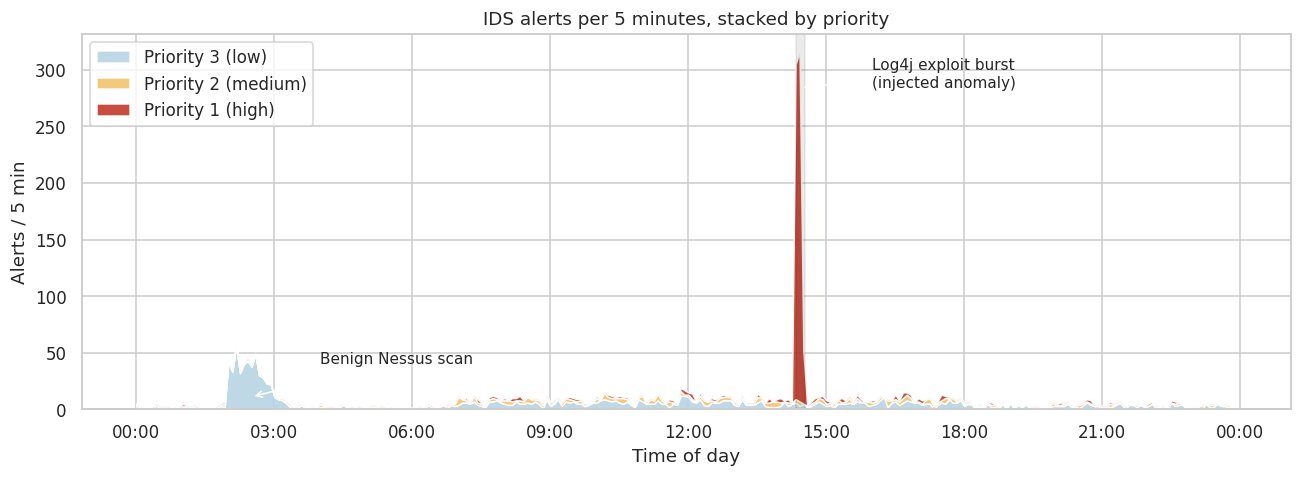

In [ ]:
per5 = (alerts.groupby(["window", "priority"]).size().unstack(fill_value=0)
        .reindex(pd.date_range(DAY, DAY + timedelta(hours=23, minutes=55), freq="5min"), fill_value=0))
per5 = per5.rename(columns={1: "Priority 1 (high)", 2: "Priority 2 (medium)", 3: "Priority 3 (low)"})

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.stackplot(per5.index, per5["Priority 3 (low)"], per5["Priority 2 (medium)"], per5["Priority 1 (high)"],
             labels=["Priority 3 (low)", "Priority 2 (medium)", "Priority 1 (high)"],
             colors=["#B8D4E3", "#F2C46D", RED], alpha=0.9)
ax.legend(loc="upper left")
ax.axvspan(ATTACK_START, ATTACK_START + timedelta(minutes=12), color="black", alpha=0.08)
ax.annotate("Log4j exploit burst\n(injected anomaly)", xy=(ATTACK_START + timedelta(minutes=6), per5.sum(axis=1).max()*0.9),
            xytext=(DAY + timedelta(hours=16), per5.sum(axis=1).max()*0.9),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate("Benign Nessus scan", xy=(DAY + timedelta(hours=2, minutes=30), 11),
            xytext=(DAY + timedelta(hours=4), 40), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_title("IDS alerts per 5 minutes, stacked by priority"); ax.set_xlabel("Time of day"); ax.set_ylabel("Alerts / 5 min")
plt.tight_layout(); plt.savefig("figures/01_alerts_timeline.png", dpi=150); plt.show()

**Reading the chart:** a large red (priority-1) spike appears at 14:20–14:35, far above the normal background. The 02:00–03:00 scanner produces a sustained plateau of *low-priority* alerts, which is visible but harmless.

## 5. Visualization 2 — Heatmap: signature × hour
Questions answered: *which* attack type is responsible, and when is it concentrated?

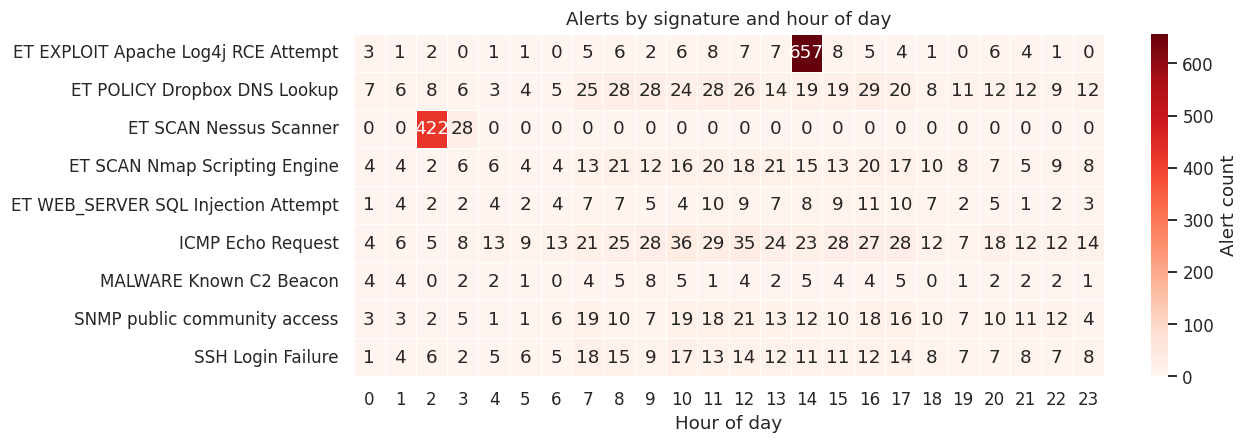

In [ ]:
pivot = alerts.pivot_table(index="signature", columns=alerts["timestamp"].dt.hour,
                           values="src_ip", aggfunc="count", fill_value=0)
plt.figure(figsize=(12, 4.2))
sns.heatmap(pivot, cmap="Reds", annot=True, fmt="d", linewidths=.4, cbar_kws={"label": "Alert count"})
plt.title("Alerts by signature and hour of day"); plt.xlabel("Hour of day"); plt.ylabel("")
plt.tight_layout(); plt.savefig("figures/02_signature_hour_heatmap.png", dpi=150); plt.show()

**Reading the chart:** hour 14 is dominated by one cell, the *Log4j RCE* signature, while hour 2 lights up on *Nessus Scanner*. The heatmap names the attack type, which the timeline cannot.

## 6. Visualization 3 — Who is responsible? Volume vs. severity
Left: top sources ranked by **all** alerts. Right: top sources ranked by **priority-1** alerts only. This explains why the detection rule uses severity and not raw volume.

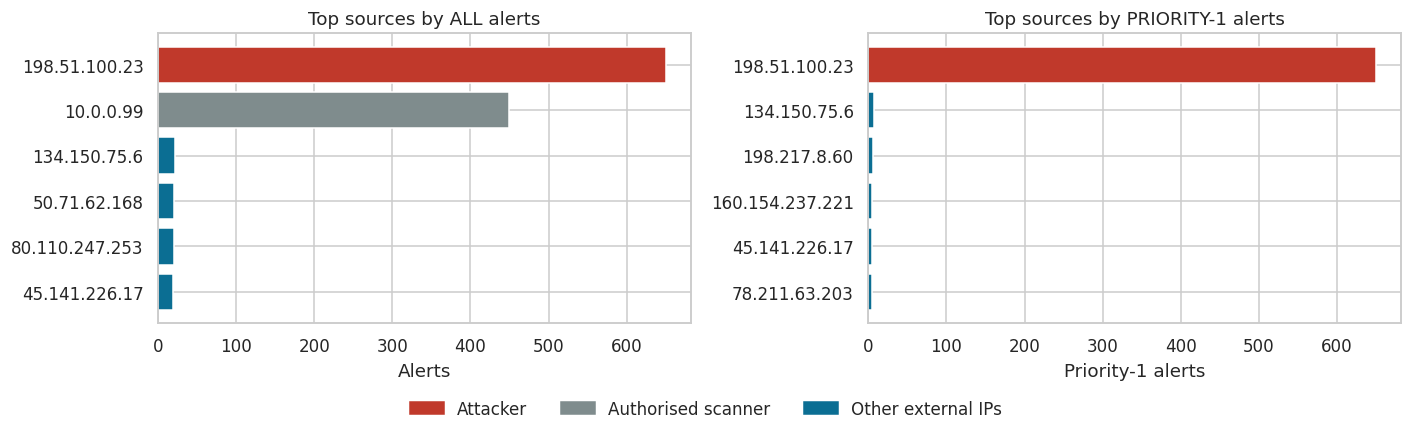

In [ ]:
top_all = alerts["src_ip"].value_counts().head(6)
top_p1 = alerts[alerts["priority"] == 1]["src_ip"].value_counts().head(6)
col = lambda idx: [RED if ip == ATTACKER_IP else (GREY if ip == SCANNER_IP else BLUE) for ip in idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(top_all.index, top_all.values, color=col(top_all.index)); axes[0].invert_yaxis()
axes[0].set_title("Top sources by ALL alerts"); axes[0].set_xlabel("Alerts")
axes[1].barh(top_p1.index, top_p1.values, color=col(top_p1.index)); axes[1].invert_yaxis()
axes[1].set_title("Top sources by PRIORITY-1 alerts"); axes[1].set_xlabel("Priority-1 alerts")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=RED, label="Attacker"), Patch(color=GREY, label="Authorised scanner"),
                    Patch(color=BLUE, label="Other external IPs")], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.savefig("figures/03_top_sources_volume_vs_severity.png", dpi=150); plt.show()

**Reading the chart:** by raw volume the scanner (grey) looks like the second-biggest threat. By severity it disappears, and the attacker (red) stands far above every other IP.

## 7. Detection rule
> **Rule:** raise an alert when a single source IP generates **at least `T` priority-1 alerts within one 5-minute window.**

Why this rule: it uses severity (ignores the noisy scanner) and rate (ignores the occasional isolated priority-1 alert in normal traffic). We choose `T = 15` after looking at the data: normal sources have at most 1–3 priority-1 alerts per window.

In [ ]:
# How many priority-1 alerts does a *normal* (src, window) pair produce? -> guides the choice of T
normal_p1 = (alerts[(alerts.priority == 1) & (~alerts.is_attack)].groupby(["src_ip", "window"]).size())
print("Normal data, priority-1 alerts per (IP, 5-min window): max =", normal_p1.max())
attack_p1 = alerts[alerts.is_attack].groupby(["src_ip", "window"]).size()
print("Attack data, per (IP, 5-min window):\n", attack_p1)

Normal data, priority-1 alerts per (IP, 5-min window): max = 2
Attack data, per (IP, 5-min window):
 src_ip         window             
198.51.100.23  2026-10-19 14:20:00    295
               2026-10-19 14:25:00    308
               2026-10-19 14:30:00     47
dtype: int64


In [ ]:
WINDOW = "5min"
THRESHOLD = 15

def apply_rule(df, threshold=THRESHOLD):
    """Return df with a boolean column 'flagged': True if the alert belongs to a
    (src_ip, window) group with >= threshold priority-1 alerts."""
    out = df.copy()
    p1_counts = out[out.priority == 1].groupby(["src_ip", "window"]).size()
    bad_groups = p1_counts[p1_counts >= threshold].index
    key = pd.MultiIndex.from_frame(out[["src_ip", "window"]])
    out["flagged"] = (out.priority == 1) & key.isin(bad_groups)
    return out

detected = apply_rule(alerts)
summary = (detected[detected.flagged].groupby(["window", "src_ip"]).size()
           .rename("p1_alerts").reset_index())
print("Alerts raised by the rule:"); summary

Alerts raised by the rule:


,window,src_ip,p1_alerts
0,2026-10-19 14:20:00,198.51.100.23,295
1,2026-10-19 14:25:00,198.51.100.23,308
2,2026-10-19 14:30:00,198.51.100.23,47


## 8. Evaluation of the rule
We evaluate three ways:
1. **Anomalous day** — confusion matrix and metrics (alert level).
2. **Normal-only day** — a different day with no attack, to count false alarms.
3. **Threshold sensitivity** — how the choice of `T` affects the result.

=== Day WITH attack ===
TP        : 650
FP        : 0
FN        : 0
TN        : 2250
Precision : 1.0000
Recall    : 1.0000
F1        : 1.0000
FPR       : 0.0000


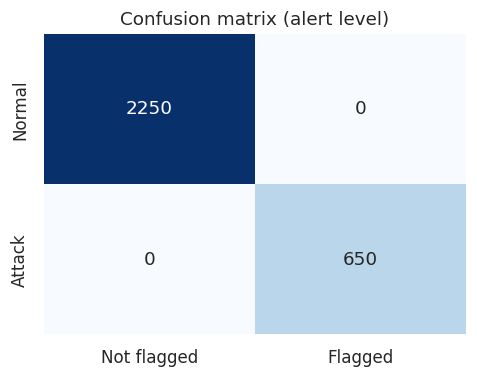

In [ ]:
def evaluate(df):
    tp = int(((df.flagged) & (df.is_attack)).sum());  fp = int(((df.flagged) & (~df.is_attack)).sum())
    fn = int(((~df.flagged) & (df.is_attack)).sum()); tn = int(((~df.flagged) & (~df.is_attack)).sum())
    prec = tp / (tp + fp) if tp + fp else float("nan")
    rec  = tp / (tp + fn) if tp + fn else float("nan")
    f1   = 2*prec*rec/(prec+rec) if tp else float("nan")
    fpr  = fp / (fp + tn) if fp + tn else float("nan")
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, Precision=prec, Recall=rec, F1=f1, FPR=fpr)

# ---- 8.1 Anomalous day
res_attack = evaluate(detected)
print("=== Day WITH attack ===")
for k, v in res_attack.items(): print(f"{k:10s}: {v:.4f}" if isinstance(v, float) else f"{k:10s}: {v}")

cm = np.array([[res_attack["TN"], res_attack["FP"]], [res_attack["FN"], res_attack["TP"]]])
plt.figure(figsize=(4.5, 3.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not flagged", "Flagged"], yticklabels=["Normal", "Attack"])
plt.title("Confusion matrix (alert level)"); plt.tight_layout()
plt.savefig("figures/04_confusion_matrix.png", dpi=150); plt.show()

In [ ]:
# ---- 8.2 Normal-only days (several seeds, no injected attack)
rows = []
for seed in [101, 102, 103, 104, 105]:
    day_normal = apply_rule(generate_alerts(seed, inject_attack=False))
    rows.append({"seed": seed, "alerts": len(day_normal), "flagged": int(day_normal.flagged.sum()),
                 "false_positives": int((day_normal.flagged & ~day_normal.is_attack).sum())})
normal_report = pd.DataFrame(rows)
print("=== Normal-only days (no attack) ===")
display(normal_report)
print("Total false alarms over 5 normal days:", normal_report.false_positives.sum())

=== Normal-only days (no attack) ===


,seed,alerts,flagged,false_positives
0,101,2250,0,0
1,102,2250,0,0
2,103,2250,0,0
3,104,2250,0,0
4,105,2250,0,0


Total false alarms over 5 normal days: 0


,T,Precision,Recall,F1,FP (attack day),FP (normal day)
0,1,0.700,1.000,0.823,279,320
1,2,0.997,1.000,0.998,2,2
2,3,1.000,1.000,1.000,0,0
3,5,1.000,1.000,1.000,0,0
4,8,1.000,1.000,1.000,0,0
5,10,1.000,1.000,1.000,0,0
6,15,1.000,1.000,1.000,0,0
7,20,1.000,1.000,1.000,0,0
8,30,1.000,1.000,1.000,0,0
9,50,1.000,0.928,0.962,0,0


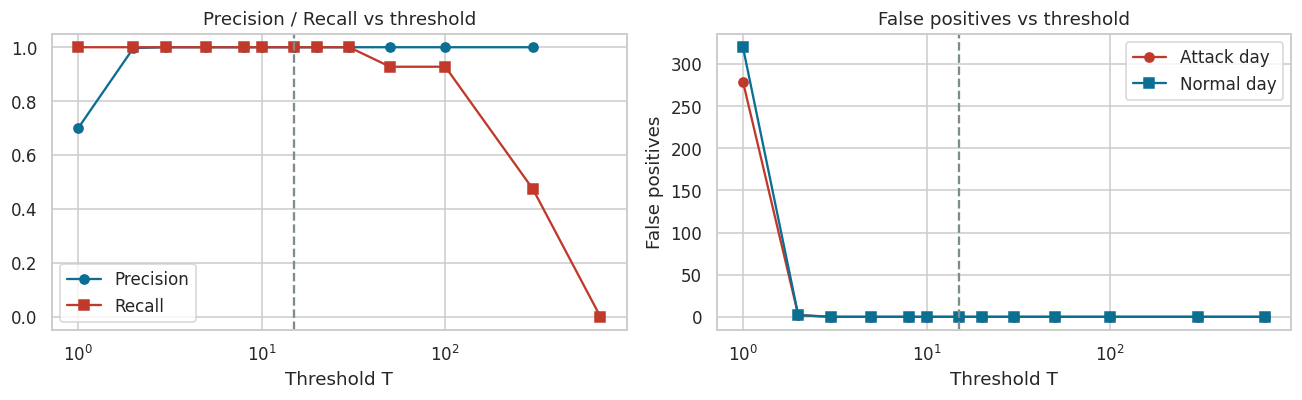

In [ ]:
# ---- 8.3 Sensitivity to the threshold T
rows = []
normal_day = generate_alerts(101, inject_attack=False)
for T in [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 100, 300, 700]:
    a = evaluate(apply_rule(alerts, T)); n = evaluate(apply_rule(normal_day, T))
    rows.append({"T": T, "Precision": a["Precision"], "Recall": a["Recall"], "F1": a["F1"],
                 "FP (attack day)": a["FP"], "FP (normal day)": n["FP"]})
sens = pd.DataFrame(rows); display(sens.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(sens["T"], sens["Precision"], "o-", label="Precision", color=BLUE)
ax[0].plot(sens["T"], sens["Recall"], "s-", label="Recall", color=RED)
ax[0].set_xscale("log"); ax[0].axvline(THRESHOLD, ls="--", color=GREY); ax[0].set_xlabel("Threshold T"); ax[0].legend()
ax[0].set_title("Precision / Recall vs threshold")
ax[1].plot(sens["T"], sens["FP (attack day)"], "o-", label="Attack day", color=RED)
ax[1].plot(sens["T"], sens["FP (normal day)"], "s-", label="Normal day", color=BLUE)
ax[1].set_xscale("log"); ax[1].axvline(THRESHOLD, ls="--", color=GREY); ax[1].set_xlabel("Threshold T")
ax[1].set_ylabel("False positives"); ax[1].legend(); ax[1].set_title("False positives vs threshold")
plt.tight_layout(); plt.savefig("figures/05_threshold_sensitivity.png", dpi=150); plt.show()

In [ ]:
# ---- 8.4 Baseline comparison: a naive volume-only rule (any source with >= 15 alerts of ANY priority / 5 min)
def naive_volume_rule(df, threshold=15):
    out = df.copy()
    counts = out.groupby(["src_ip", "window"]).size()
    bad = counts[counts >= threshold].index
    out["flagged"] = pd.MultiIndex.from_frame(out[["src_ip", "window"]]).isin(bad)
    return out

naive = evaluate(naive_volume_rule(alerts))
cmp = pd.DataFrame({"Priority-1 rate rule (ours)": res_attack, "Naive volume rule": naive}).T
display(cmp.round(3))

,TP,FP,FN,TN,Precision,Recall,F1,FPR
Priority-1 rate rule (ours),650.0,0.0,0.0,2250.0,1.000,1.0,1.000,0.000
Naive volume rule,650.0,422.0,0.0,1828.0,0.606,1.0,0.755,0.188


## 9. Main findings
1. **Anomaly location.** The injected Log4j RCE burst occurs on 19 Oct 2026 at **14:20–14:31**, from `198.51.100.23`, against `10.0.0.50/51` on ports 443/8080 (650 priority-1 alerts, which is the whole attack).
2. **Visual evidence.** The timeline shows a red spike, the heatmap isolates the signature, and the source comparison shows the attacker dominating on severity.
3. **Volume is misleading.** The authorised Nessus scanner (`10.0.0.99`) generates a comparable number of alerts. The naive volume rule flags it (false positives), while the severity-aware rule does not.
4. **Detection rule.** *≥ 15 priority-1 alerts from one IP in a 5-minute window* detects all attack alerts (recall = 1.0) with no false positives on the attack day and on five normal-only days. The naive volume-only rule also reaches recall 1.0 but flags the scanner, so its precision falls to about 0.61.
5. **Threshold choice.** Results are perfect for any `T` between 3 and 30. At `T = 1` or `2`, isolated normal priority-1 alerts trigger the rule (precision drops to 0.70 at `T = 1`). At `T ≥ 50` the last, partial attack window (47 alerts) is missed and recall drops to 0.93.